In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys, os
# add the repo root (the folder containing config.py) to the path, from any depth
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "config.py")) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)

sites with >=3 observations: 102


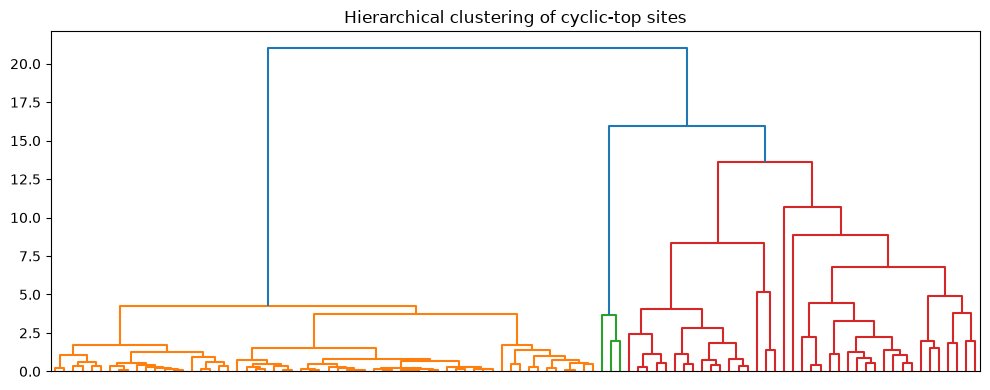

         current_amp  mean_amp  max_amp  volatility  slope_overall  \
cluster                                                              
1              15.51     15.49    16.77        0.73           0.03   
2              49.23     46.59    54.70        5.85           0.14   
3              25.01     21.63    25.64        2.71           0.40   
4              18.67     20.84    27.02        3.99          -0.08   

         slope_current  n_resets  n_obs  
cluster                                  
1                 0.03      0.00   9.80  
2                 0.14      0.00  12.00  
3                 0.59      0.06  10.59  
4                 0.87      1.27  11.86  

cluster sizes:
 cluster
1    60
2     3
3    17
4    22


In [ ]:
import config, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from cprics.io_data import load_peak_amplitudes
from cprics.islands import build_all_islands
from cprics.tracking import track_islands
from cprics.features import build_feature_table
from cprics.classify import cluster_sites, describe_clusters

isl   = track_islands(build_all_islands(load_peak_amplitudes(config.PEAK_AMP_DIR, "9_top_right"), 9))
feats = build_feature_table(isl, min_obs=3)
print("sites with >=3 observations:", len(feats))

clustered, Z = cluster_sites(feats, n_clusters=4)
plt.figure(figsize=(10, 4))
dendrogram(Z, no_labels=True)
plt.title("Hierarchical clustering of cyclic-top sites"); plt.tight_layout(); plt.show()

print(describe_clusters(clustered))
print("\ncluster sizes:\n", clustered.cluster.value_counts().sort_index().to_string())

In [2]:
# which archetypes actually escalate to category I?
reach = isl.groupby("site_id")["amplitude"].max().ge(30).rename("reaches_I")
c = clustered.merge(reach, on="site_id")
print(c.groupby("cluster")["reaches_I"].agg(["mean", "sum", "count"]).round(2))

         mean  sum  count
cluster                  
1        0.00    0     60
2        1.00    3      3
3        0.18    3     17
4        0.23    5     22


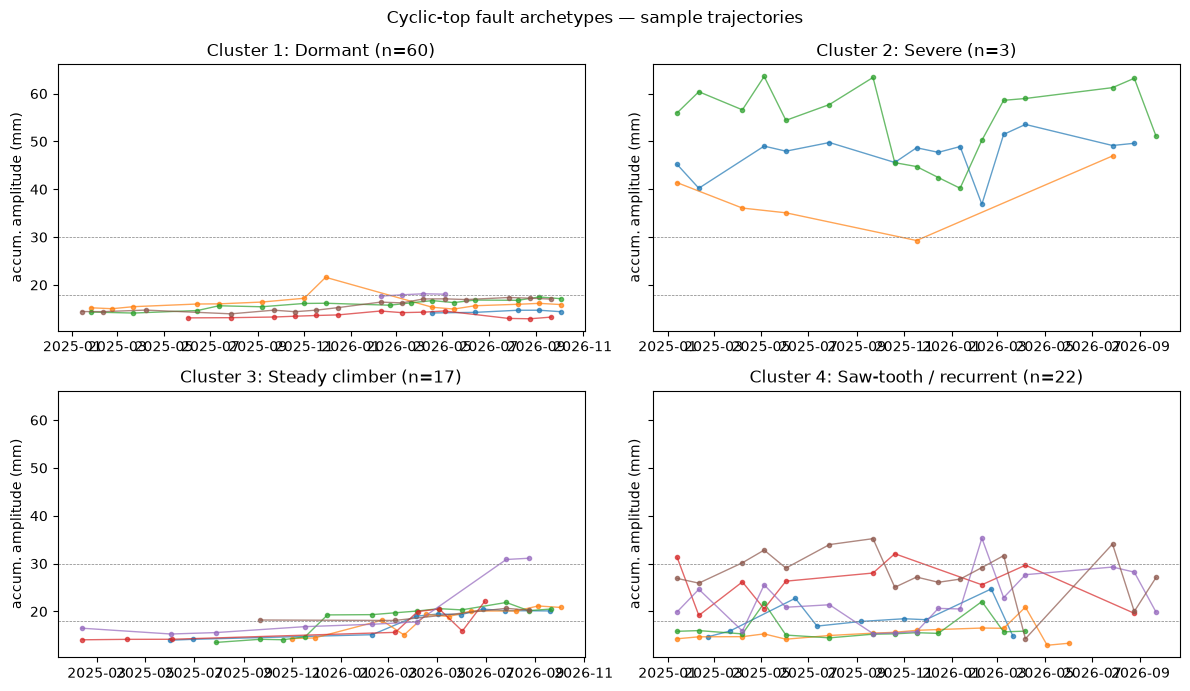

In [3]:
# see the archetypes: sample trajectories from each cluster
from cprics.series import site_trajectory
names = {1: "Dormant", 2: "Severe", 3: "Steady climber", 4: "Saw-tooth / recurrent"}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, cl in zip(axes.ravel(), sorted(clustered.cluster.unique())):
    for s in clustered[clustered.cluster == cl].site_id.head(6):
        t = site_trajectory(isl, s)
        ax.plot(t.date, t.amplitude, "o-", lw=1, ms=3, alpha=0.7)
    for thr in (18, 30):
        ax.axhline(thr, ls="--", lw=0.5, color="grey")
    ax.set_title(f"Cluster {cl}: {names[cl]} (n={(clustered.cluster==cl).sum()})")
    ax.set_ylabel("accum. amplitude (mm)")
fig.suptitle("Cyclic-top fault archetypes — sample trajectories")
fig.tight_layout(); plt.show()

In [4]:
clustered["archetype"] = clustered.cluster.map(
    {1: "Dormant", 2: "Severe", 3: "Steady climber", 4: "Saw-tooth"})
tier = {2: "1 · act now", 3: "2 · proactive watch", 4: "3 · review renewal", 1: "4 · monitor"}
clustered["priority"] = clustered.cluster.map(tier)

watch = clustered.sort_values(["priority", "current_amp", "slope_current"],
                              ascending=[True, False, False])
print(watch[["site_id", "archetype", "priority", "current_amp",
             "slope_current", "n_resets"]].head(20).to_string(index=False))

# the difference, in one view: climbing sites still BELOW the action level
proactive = clustered[(clustered.cluster == 3) & (clustered.current_amp < 26)]
print(f"\nProactive watchlist — climbing, still below action (A=26): {len(proactive)} sites")
print(proactive.sort_values("slope_current", ascending=False)
      [["site_id", "current_amp", "slope_current"]].to_string(index=False))

         site_id      archetype            priority  current_amp  slope_current  n_resets
 CNB3_3400_9R_72         Severe         1 · act now    51.102150      -0.107559         0
 CNB1_1100_9R_42         Severe         1 · act now    49.614008       0.233858         0
 CNB1_3400_9R_66         Severe         1 · act now    46.963618       0.289007         0
CWK1_2100_9R_106 Steady climber 2 · proactive watch    40.872811       3.893367         1
 CRR2_1100_9R_91 Steady climber 2 · proactive watch    32.674975       0.748706         0
 CNB1_1100_9R_41 Steady climber 2 · proactive watch    31.118851       0.747673         0
 CRR2_1100_9R_98 Steady climber 2 · proactive watch    28.841838       0.374727         0
NMC1_3400_9R_144 Steady climber 2 · proactive watch    27.653879       0.272072         0
CWK2_2100_9R_119 Steady climber 2 · proactive watch    26.475759       0.174287         0
NMC1_3400_9R_145 Steady climber 2 · proactive watch    23.588401       0.035259         0
NMC1_3400_